# Pergunta 1.4: visualizações para o time de marketing

> **Pergunta do case:** crie pelo menos 3 visualizações que você usaria para apresentar insights a um time de marketing.

Estas três figuras são para **apresentar**, não para explorar. Regras que segui em todas:
- **o título é a conclusão**, não a descrição (por exemplo, "o gancho é o que mais sobe a nota", e não "klike_score por has_hook");
- sem termos técnicos no título; o rodapé diz quantos criativos e de onde vem o dado;
- **cada plataforma tem sempre a mesma cor**; o que importa vem em uma cor e o resto em cinza;
- os valores aparecem escritos nas barras, e as fontes têm pelo menos 11 pt (legíveis num slide).

As figuras são salvas em `reports/figures/` com `fig.savefig` (função do matplotlib que grava o gráfico num arquivo .png). A explicação de cada escolha está em `docs/parte1/1_4_visualizacoes_marketing.md`.

## Passo 0: preparação

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RAIZ = Path("../..")
sys.path.append(str(RAIZ))
from src.limpeza import carregar, limpar, separar_treino_teste

AZUL, CINZA, CINZA_CLARO = "#2a78d6", "#52514e", "#b8b7b1"
PLATAFORMAS = ["Meta", "TikTok", "LinkedIn"]
CORES_PLATAFORMA = {"Meta": "#2a78d6", "TikTok": "#eb6834", "LinkedIn": "#1baf7a"}
PASTA_FIGURAS = RAIZ / "reports/figures"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left"})


def estilo_limpo(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)


def rodape(fig, texto):
    fig.text(0.01, -0.03, texto + " Fonte: dataset Klike Challenge, treino (400 criativos simulados, 2024).",
             fontsize=11, color=CINZA, ha="left", va="top")


def diferenca_mediana(dados, coluna, metrica):
    """Diferença % entre a mediana com e sem o atributo (com ÷ sem − 1), como nos notebooks 1.2 e 1.3."""
    com, sem = dados.loc[dados[coluna] == True, metrica].dropna(), dados.loc[dados[coluna] == False, metrica].dropna()
    return (com.median() / sem.median() - 1) * 100, len(com), len(sem)

In [2]:
# Mesma divisão e limpeza do notebook 1.1; valores preenchidos voltam a vazio (como nos notebooks 1.2 e 1.3)
treino_bruto, teste_bruto = separar_treino_teste(carregar(RAIZ / "data/raw/klike_challenge_dataset.csv"))
reais = limpar(treino_bruto)
for coluna in ["video_duration_s", "music_voice_ratio", "avg_watch_time_s", "engagement_rate"]:
    reais.loc[reais[f"{coluna}_faltava"] == 1, coluna] = np.nan
reais["legenda"] = reais["has_subtitle"].map({"sim": True, "nao": False})
reais["muito_texto"] = reais["text_density"] == "high"
reais["mais_musica_que_voz"] = (reais["music_voice_ratio"] > 0.5).where(reais["music_voice_ratio"].notna())
ATRIBUTOS = {"Gancho nos 3 primeiros segundos": "has_hook", "Rosto humano": "has_face", "Chamada para ação (CTA)": "has_cta",
             "Legenda": "legenda", "Mais música que voz": "mais_musica_que_voz", "Muito texto na tela": "muito_texto"}

## Figura 1: o que mover no criativo

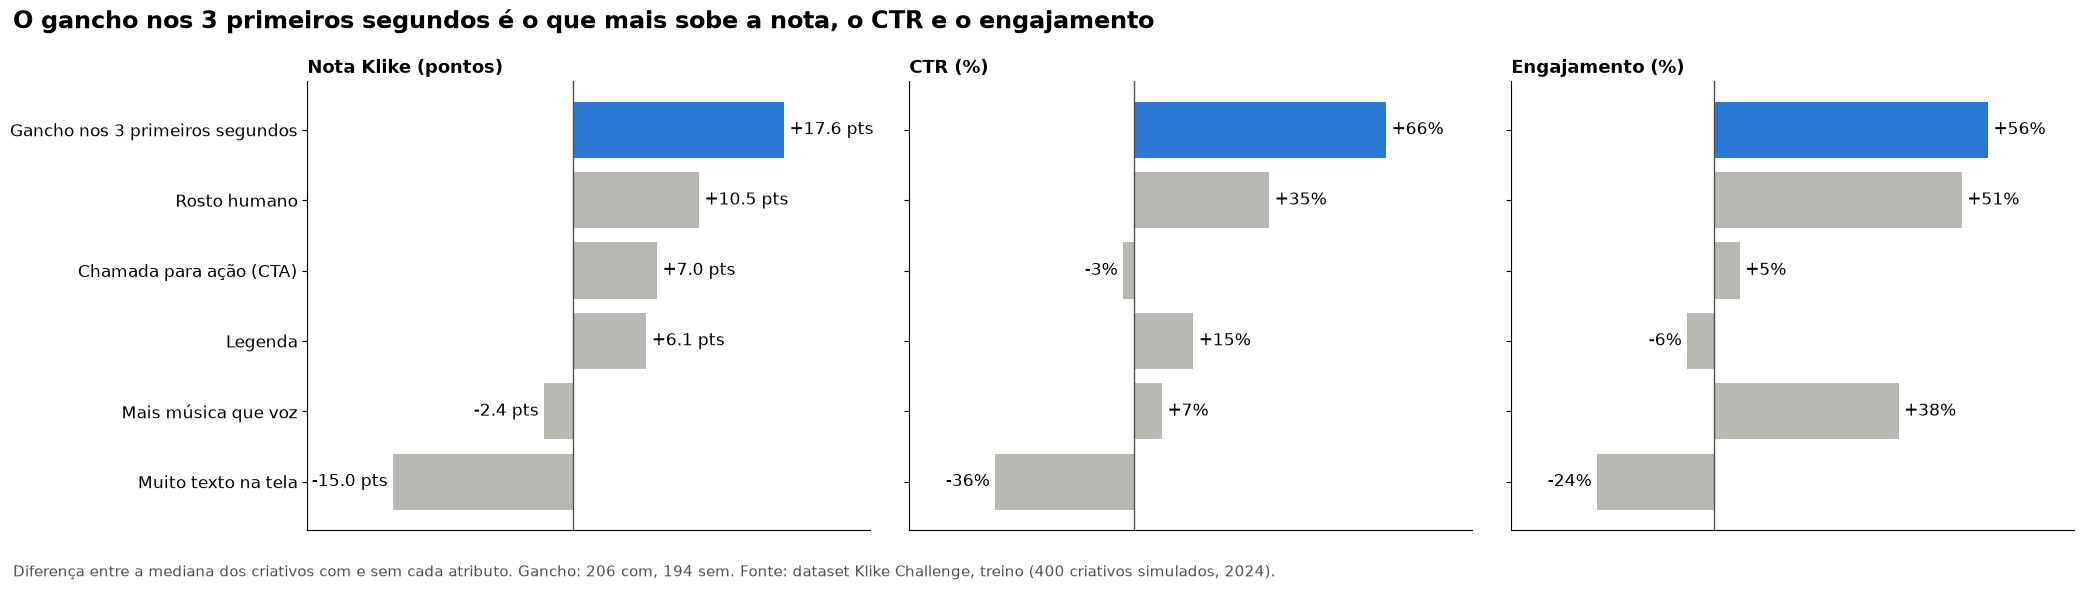

In [3]:
def diferenca_pontos(dados, coluna, metrica):
    """Na nota, a diferença em pontos (mediana com − mediana sem) é mais fácil de ler que em %."""
    return dados.loc[dados[coluna] == True, metrica].median() - dados.loc[dados[coluna] == False, metrica].median()


fig, eixos = plt.subplots(1, 3, figsize=(21, 5.5), sharey=True)
# A mesma ordem nos três painéis (pela nota), para cada linha ser o mesmo atributo
ordem = pd.Series({rotulo: diferenca_pontos(reais, coluna, "klike_score") for rotulo, coluna in ATRIBUTOS.items()}).sort_values().index
for ax, (metrica, nome) in zip(eixos, [("klike_score", "Nota Klike (pontos)"), ("ctr", "CTR (%)"), ("engagement_rate", "Engajamento (%)")]):
    if metrica == "klike_score":
        efeito = pd.Series({rotulo: diferenca_pontos(reais, coluna, metrica) for rotulo, coluna in ATRIBUTOS.items()}).loc[ordem]
        textos = [f"{v:+.1f} pts" for v in efeito.values]
    else:
        efeito = pd.Series({rotulo: diferenca_mediana(reais, coluna, metrica)[0] for rotulo, coluna in ATRIBUTOS.items()}).loc[ordem]
        textos = [f"{v:+.0f}%" for v in efeito.values]
    cores = [AZUL if rotulo == efeito.idxmax() else CINZA_CLARO for rotulo in efeito.index]
    barras = ax.barh(efeito.index, efeito.values, color=cores)
    ax.bar_label(barras, labels=textos, padding=4, fontsize=12)
    ax.axvline(0, color=CINZA, linewidth=1)
    ax.set_title(nome, fontsize=13)
    ax.set_xticks([])
    ax.margins(x=0.22)
    estilo_limpo(ax)
fig.suptitle("O gancho nos 3 primeiros segundos é o que mais sobe a nota, o CTR e o engajamento", x=0.01, ha="left",
             fontsize=17, fontweight="bold")
rodape(fig, "Diferença entre a mediana dos criativos com e sem cada atributo. Gancho: 206 com, 194 sem.")
plt.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig1_o_que_mover_no_criativo.png", dpi=150, bbox_inches="tight")
plt.show()

**Como eu apresentaria:** "Se vocês só puderem mudar uma coisa no próximo vídeo, coloquem um gancho nos 3 primeiros segundos: os vídeos com gancho têm nota mediana uns 18 pontos maior, CTR 66% maior e engajamento 56% maior. Rosto humano é a segunda alavanca. E muito texto na tela vai na direção contrária: tira uns 15 pontos de nota e derruba o CTR em um terço."

## Figura 2: o que funciona em cada rede

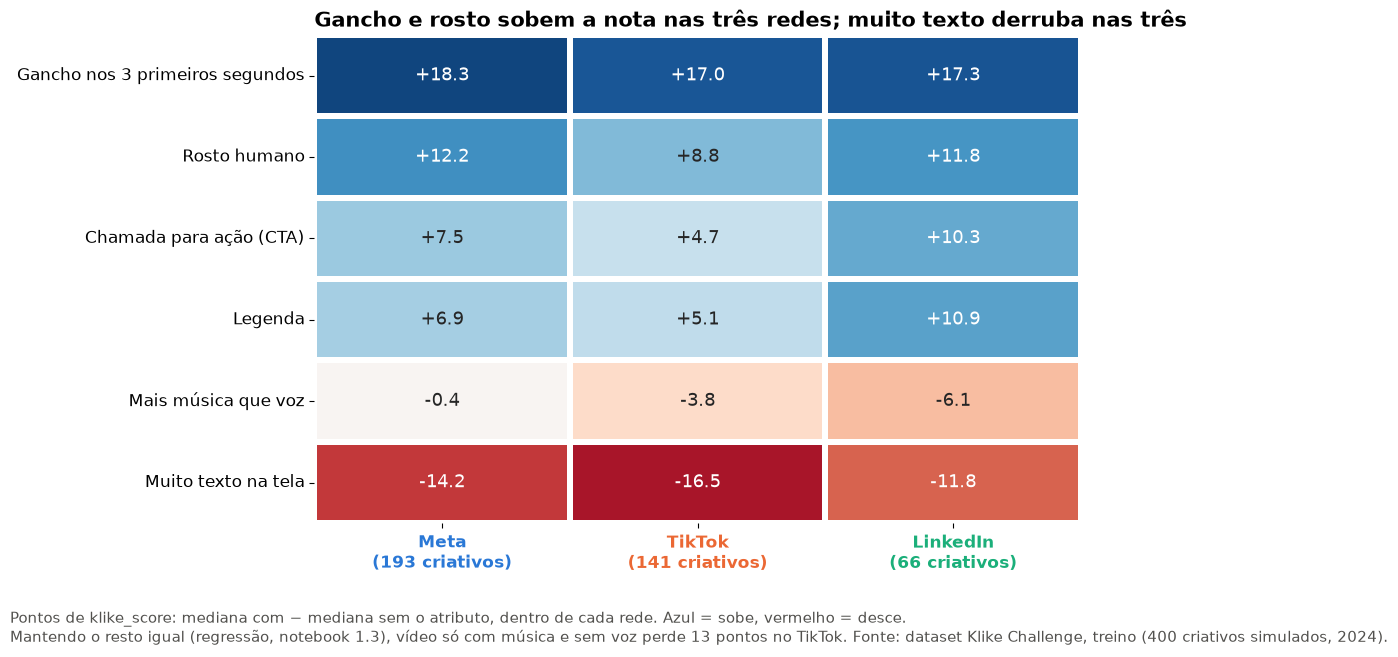

Menor grupo de cada célula: 16 criativos


In [4]:
pontos, contagem = {}, {}
for plataforma in PLATAFORMAS:
    parte = reais[reais["platform"] == plataforma]
    for rotulo, coluna in ATRIBUTOS.items():
        com, sem = parte.loc[parte[coluna] == True, "klike_score"], parte.loc[parte[coluna] == False, "klike_score"]
        pontos[(rotulo, plataforma)] = com.median() - sem.median()
        contagem[(rotulo, plataforma)] = min(com.notna().sum(), sem.notna().sum())
pontos = pd.Series(pontos).unstack()[PLATAFORMAS].loc[list(ATRIBUTOS)]
contagem = pd.Series(contagem).unstack()[PLATAFORMAS].loc[list(ATRIBUTOS)]

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(pontos, annot=pontos.map(lambda v: f"{v:+.1f}"), fmt="", cmap="RdBu", center=0, vmin=-20, vmax=20,
            cbar=False, ax=ax, linewidths=3, linecolor="white", annot_kws={"fontsize": 13})
ax.set_xticklabels([f"{p}\n({(reais['platform'] == p).sum()} criativos)" for p in PLATAFORMAS], rotation=0, fontsize=12)
for rotulo_x, plataforma in zip(ax.get_xticklabels(), PLATAFORMAS):
    rotulo_x.set_color(CORES_PLATAFORMA[plataforma])
    rotulo_x.set_fontweight("bold")
ax.set_ylabel("")
ax.set_title("Gancho e rosto sobem a nota nas três redes; muito texto derruba nas três", fontsize=15)
rodape(fig, "Pontos de klike_score: mediana com − mediana sem o atributo, dentro de cada rede. Azul = sobe, vermelho = desce.\n"
            "Mantendo o resto igual (regressão, notebook 1.3), vídeo só com música e sem voz perde 13 pontos no TikTok.")
plt.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig2_o_que_funciona_em_cada_rede.png", dpi=150, bbox_inches="tight")
plt.show()
print("Menor grupo de cada célula:", int(contagem.min().min()), "criativos")

**Como eu apresentaria:** "A boa notícia é que o básico vale em todas as redes: gancho soma uns 17 pontos de nota, rosto uns 10, e muito texto tira de 12 a 16. A exceção que vale ouro é o TikTok: lá, vídeo só com música e sem voz perde 13 pontos. No TikTok, coloquem voz."

## Figura 3: o vídeo decide o clique; a venda depende do público

O marketing costuma cobrar do criativo a venda. Esta figura mostra **onde, no funil, cada coisa pesa**: três atributos do vídeo e o tipo de público (retargeting), da atenção (CTR, retenção) à venda (taxa de conversão, CPA, ROAS). Só pinto as células em que a diferença é confiável (intervalo de 95% por bootstrap, como no notebook 1.2); as brancas podem ser acaso.

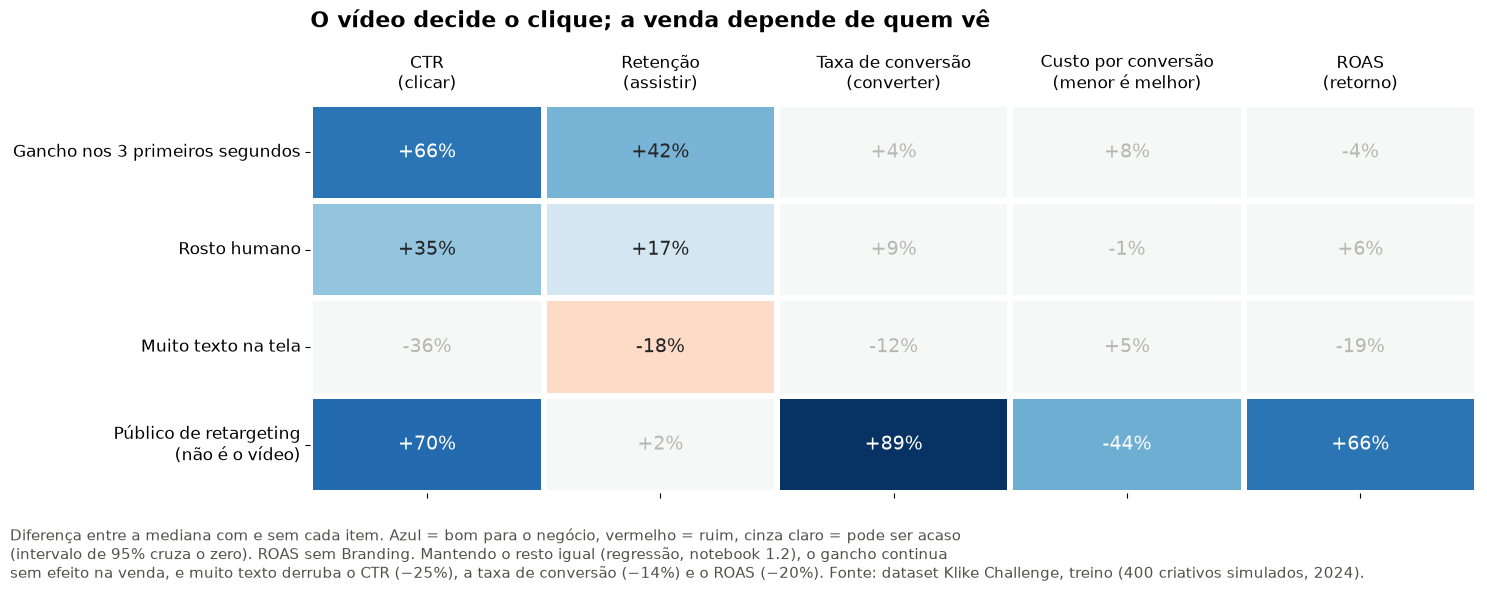

,CTR\n(clicar),Retenção\n(assistir),Taxa de conversão\n(converter),Custo por conversão\n(menor é melhor),ROAS\n(retorno)
Gancho nos 3 primeiros segundos,66.0,42.0,4.0,8.0,-4.0
Rosto humano,35.0,17.0,9.0,-1.0,6.0
Muito texto na tela,-36.0,-18.0,-12.0,5.0,-19.0
Público de retargeting\n(não é o vídeo),70.0,2.0,89.0,-44.0,66.0


In [5]:
def diferenca_com_intervalo(dados, coluna, metrica, sorteios=2000):
    """Diferença % das medianas e se o intervalo de 95% (bootstrap) fica de um lado do zero."""
    com = dados.loc[dados[coluna] == True, metrica].dropna().to_numpy()
    sem = dados.loc[dados[coluna] == False, metrica].dropna().to_numpy()
    gerador = np.random.default_rng(42)
    medianas_com = np.median(com[gerador.integers(0, len(com), (sorteios, len(com)))], axis=1)
    medianas_sem = np.median(sem[gerador.integers(0, len(sem), (sorteios, len(sem)))], axis=1)
    baixo, alto = np.percentile((medianas_com / medianas_sem - 1) * 100, [2.5, 97.5])
    return (np.median(com) / np.median(sem) - 1) * 100, baixo > 0 or alto < 0


reais["retencao"] = reais["avg_watch_time_s"] / reais["video_duration_s"]
reais.loc[reais["category"] == "Branding", "roas"] = np.nan  # ROAS não se aplica a Branding
LINHAS_FUNIL = {"Gancho nos 3 primeiros segundos": "has_hook", "Rosto humano": "has_face",
                "Muito texto na tela": "muito_texto", "Público de retargeting\n(não é o vídeo)": "is_retargeting"}
COLUNAS_FUNIL = {"ctr": "CTR\n(clicar)", "retencao": "Retenção\n(assistir)", "taxa_conversao": "Taxa de conversão\n(converter)",
                 "cpa": "Custo por conversão\n(menor é melhor)", "roas": "ROAS\n(retorno)"}
valores, confiavel = {}, {}
for rotulo, coluna in LINHAS_FUNIL.items():
    for metrica, nome in COLUNAS_FUNIL.items():
        valores[(rotulo, nome)], confiavel[(rotulo, nome)] = diferenca_com_intervalo(reais, coluna, metrica)
valores = pd.Series(valores).unstack().loc[list(LINHAS_FUNIL), list(COLUNAS_FUNIL.values())]
confiavel = pd.Series(confiavel).unstack().loc[list(LINHAS_FUNIL), list(COLUNAS_FUNIL.values())]
# Cor: azul = bom para o negócio (no custo por conversão, cair é bom); branco = pode ser acaso
bom = valores.copy()
bom[COLUNAS_FUNIL["cpa"]] *= -1
cor = bom.where(confiavel, 0)

fig, ax = plt.subplots(figsize=(15, 5.2))
sns.heatmap(cor, annot=valores.map(lambda v: f"{v:+.0f}%"), fmt="", cmap="RdBu", center=0, vmin=-90, vmax=90, cbar=False, ax=ax,
            linewidths=3, linecolor="white", annot_kws={"fontsize": 14})
for texto, ok in zip(ax.texts, confiavel.to_numpy().flat):
    if not ok:
        texto.set_color(CINZA_CLARO)
ax.tick_params(axis="x", labeltop=True, labelbottom=False, rotation=0, labelsize=12)
ax.tick_params(axis="y", rotation=0, labelsize=12)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("O vídeo decide o clique; a venda depende de quem vê", fontsize=16, pad=55)
rodape(fig, "Diferença entre a mediana com e sem cada item. Azul = bom para o negócio, vermelho = ruim, cinza claro = pode ser acaso\n"
            "(intervalo de 95% cruza o zero). ROAS sem Branding. Mantendo o resto igual (regressão, notebook 1.2), o gancho continua\n"
            "sem efeito na venda, e muito texto derruba o CTR (−25%), a taxa de conversão (−14%) e o ROAS (−20%).")
plt.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig3_o_video_decide_o_clique.png", dpi=150, bbox_inches="tight")
plt.show()
valores.round(0)

**Como eu apresentaria:** "O vídeo é a vitrine: ele decide se a pessoa para e clica. O gancho sobe o CTR em 66% e a retenção em 42%, mas não muda a taxa de conversão, o custo por conversão nem o ROAS. Quem mexe na venda é o público: para quem já conhece a marca (retargeting), a conversão é 89% maior, cada conversão sai 44% mais barata e o ROAS é 66% maior. Então: cobrem do criativo atenção e clique, e cobrem da segmentação e da oferta a venda. A única coisa do vídeo que atrapalha até a venda é muito texto na tela."

## Resposta à pergunta 1.4

O enunciado pede pelo menos três figuras. Escolhi três, cada uma respondendo a uma pergunta diferente do time de marketing:

| Figura | A pergunta do marketing | A mensagem | Arquivo |
|---|---|---|---|
| 1 | O que eu mudo no próximo vídeo? | O gancho é o que mais sobe a nota, o CTR e o engajamento; muito texto derruba | `reports/figures/fig1_o_que_mover_no_criativo.png` |
| 2 | Isso vale em todas as redes? | O básico funciona nas três redes; no TikTok, voz importa | `reports/figures/fig2_o_que_funciona_em_cada_rede.png` |
| 3 | O criativo vende? | O vídeo decide o clique; a venda depende de quem vê | `reports/figures/fig3_o_video_decide_o_clique.png` |

Ficaram de fora a duração ("não há duração ideal" é um resultado negativo, que cabe numa frase), o checklist (soma atributos que pesam diferente, e o peso de cada um já está na figura 1) e o texto por rede (muito texto já aparece nas figuras 1 e 2).